importing all necessary libs

In [69]:
import tensorflow as tf
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, roc_auc_score
import seaborn as sns
from sklearn.cluster import KMeans
from tensorflow.keras.layers import Layer
from tensorflow.keras import Sequential, layers
from tensorflow.keras.optimizers import SGD


import warnings
warnings.filterwarnings('ignore')

loading the data

In [70]:
df = pd.read_csv('heart+disease/processed.cleveland.data', header=None)

feature_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
df.columns = feature_names + ['target']

df = df.replace('?', np.nan).astype(float)
df = df.dropna()

df['target'] = (df['target'] > 0).astype(int)

X = df[feature_names].values
y = df['target'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.shape, X_test_scaled.shape, y_train.shape, y_test.shape

((237, 13), (60, 13), (237,), (60,))

creating a rbf layer

In [71]:
class RBFLayer(Layer):
    def __init__(self, centers, sigma, **kwargs):
        super(RBFLayer, self).__init__(**kwargs)
        self.centers = tf.constant(centers, dtype=tf.float32)
        self.sigma = sigma
    
    def call(self, x):
        distances = tf.sqrt(tf.reduce_sum((tf.expand_dims(x, 1) - self.centers) ** 2, axis=2))
        rbf_output = tf.exp(-(distances ** 2) / (2 * self.sigma ** 2))
        return rbf_output

defining the function to build and train the model

In [72]:
def build_and_train_rbf_network(X_train, X_test, y_train, y_test, k, sigma, epochs=100):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train)
    centers = kmeans.cluster_centers_
    
    model = Sequential([
        RBFLayer(centers, sigma),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train_scaled, y_train, epochs=epochs, batch_size=16, validation_split=0.2, verbose=0)
    
    y_pred_prob = model.predict(X_test_scaled, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    
    return model, history, centers, y_pred_prob, y_pred

defing the way to compute the score

In [73]:
def compute_metrics(y_true, y_pred, y_pred_prob):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_pred_prob)
    
    return {
        'confusion_matrix': cm,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1,
        'roc_auc': roc_auc
    }

printing the results of different sigma values and k values

In [74]:
k_values = [3, 5, 7]
sigma_values = [0.1, 0.5, 1.0, 2.0]

results = {}

for k in k_values:
    results[f'k_{k}'] = {}
    for sigma in sigma_values:
        model, history, centers, y_pred_prob, y_pred = build_and_train_rbf_network(X_train_scaled, X_test_scaled, y_train, y_test, k, sigma)
        metrics = compute_metrics(y_test, y_pred, y_pred_prob)
        results[f'k_{k}'][f'sigma_{sigma}'] = {
            'model': model,
            'history': history,
            'centers': centers,
            'y_pred_prob': y_pred_prob,
            'y_pred': y_pred,
            'metrics': metrics
        }

results

{'k_3': {'sigma_0.1': {'model': <Sequential name=sequential_48, built=True>,
   'history': <keras.src.callbacks.history.History at 0x12a74bb60>,
   'centers': array([[ 4.39482767e-01, -1.26356479e+00, -2.99334903e-01,
            1.30325336e-01,  4.36833604e-01, -9.46272409e-02,
            2.12349166e-04,  7.03699744e-02, -3.41941338e-01,
           -4.38876850e-01, -2.22149278e-01, -2.49869872e-01,
           -8.62587460e-01],
          [ 3.70298496e-01,  3.03132495e-01,  6.74439054e-01,
            2.37965400e-01,  5.27432800e-02,  1.68015557e-01,
            3.11583557e-01, -8.08197389e-01,  7.85217859e-01,
            7.88920181e-01,  6.72971538e-01,  5.88582117e-01,
            7.54188169e-01],
          [-5.97194134e-01,  5.36389715e-01, -3.93093771e-01,
           -2.87712452e-01, -3.21420687e-01, -8.52593812e-02,
           -2.69079922e-01,  6.53157762e-01, -4.61804044e-01,
           -4.03777304e-01, -4.40575889e-01, -3.50226750e-01,
           -1.06191393e-01]]),
   'y_pred_

calcualting the accuracy

In [75]:
accuracy_table = pd.DataFrame()

for k in k_values:
    row = {}
    row['K'] = k
    for sigma in sigma_values:
        acc = results[f'k_{k}'][f'sigma_{sigma}']['metrics']['accuracy']
        row[f'sigma={sigma}'] = round(acc, 4)
    accuracy_table = pd.concat([accuracy_table, pd.DataFrame([row])], ignore_index=True)

accuracy_table

,K,sigma=0.1,sigma=0.5,sigma=1.0,sigma=2.0
0,3,0.5333,0.5333,0.5333,0.7667
1,5,0.5333,0.5333,0.5333,0.5667
2,7,0.5333,0.5333,0.5333,0.7667


we can see the bets one is witj K=7 and sigma=2

In [76]:
cm = best_result['metrics']['confusion_matrix']
acc = best_result['metrics']['accuracy']
prec = best_result['metrics']['precision']
rec = best_result['metrics']['recall']
f1 = best_result['metrics']['f1_score']
roc_auc = best_result['metrics']['roc_auc']

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Value': [round(acc, 4), round(prec, 4), round(rec, 4), round(f1, 4), round(roc_auc, 4)]
})

metrics_df

,Metric,Value
0,Accuracy,0.6833
1,Precision,1.0000
2,Recall,0.3214
3,F1-Score,0.4865
4,ROC-AUC,0.9286


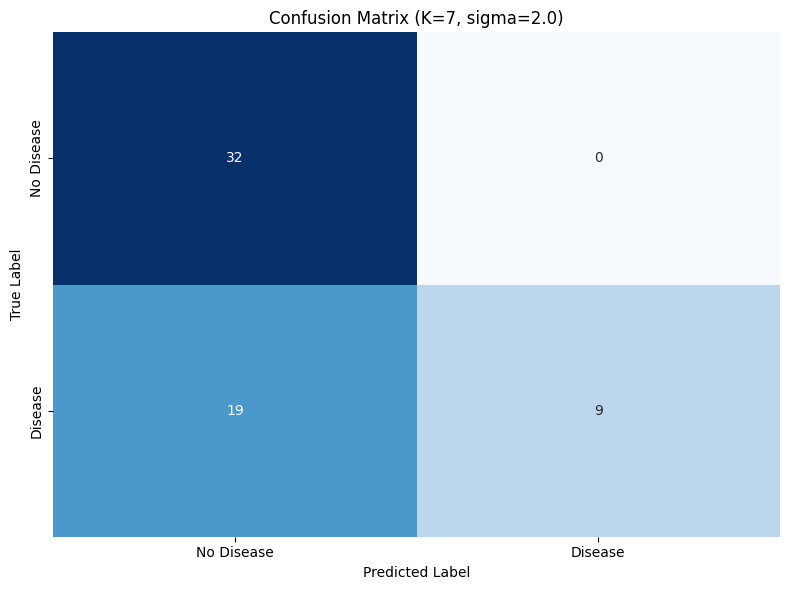

In [77]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['No Disease', 'Disease'], 
            yticklabels=['No Disease', 'Disease'])
plt.title(f'Confusion Matrix (K={best_k}, sigma={best_sigma})')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

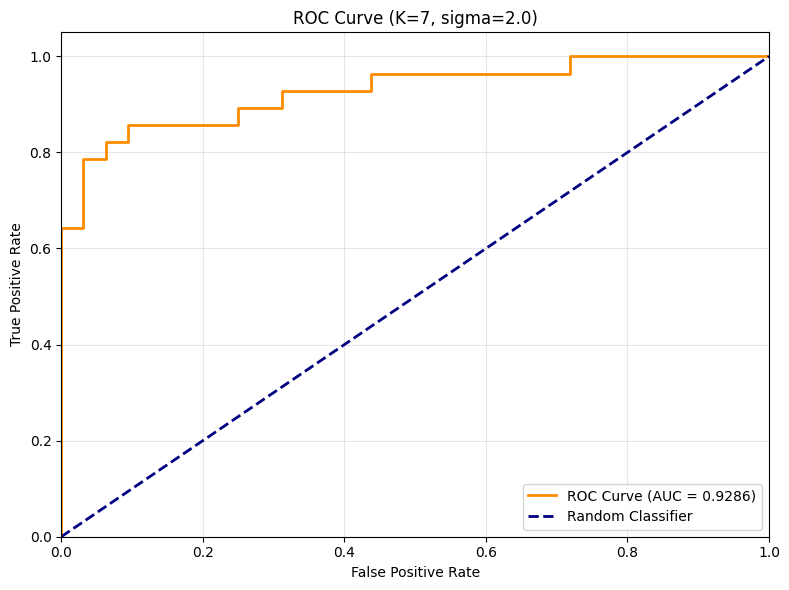

In [78]:
fpr, tpr, thresholds = roc_curve(y_test, best_result['y_pred_prob'])
auc_score = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {round(auc_score, 4)})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve (K={best_k}, sigma={best_sigma})')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

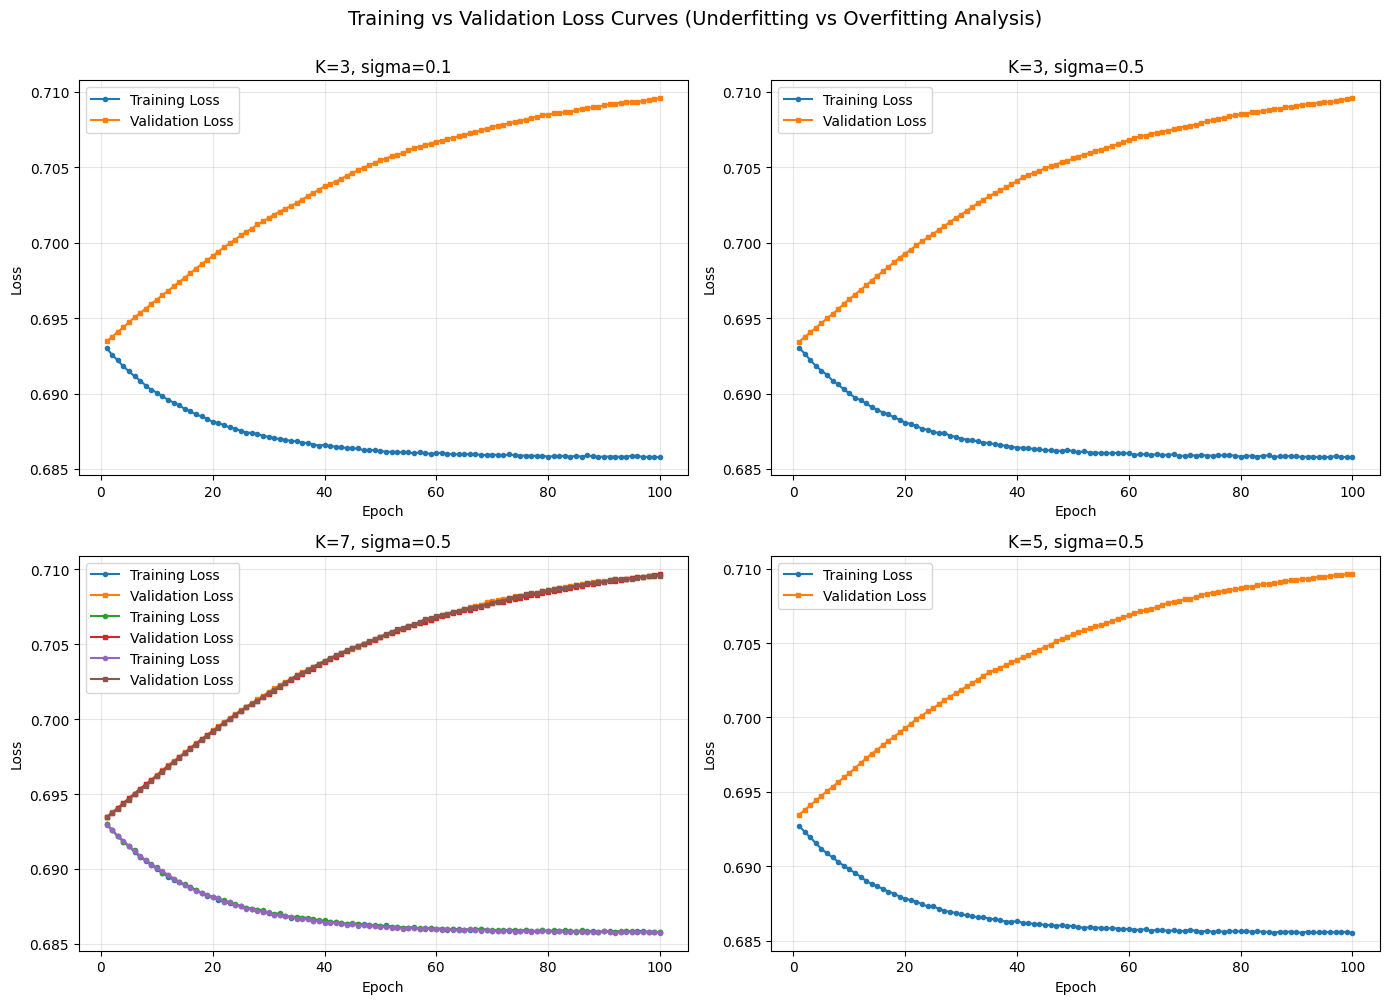

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, k in enumerate(k_values):
    for jdx, sigma in enumerate(sigma_values[:2]):
        ax = axes[idx, jdx] if idx < 2 else axes[1, 0]
        
        history = results[f'k_{k}'][f'sigma_{sigma}']['history']
        epochs_range = range(1, len(history.history['loss']) + 1)
        
        ax.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o', markersize=3)
        ax.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='s', markersize=3)
        ax.set_title(f'K={k}, sigma={sigma}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(alpha=0.3)

fig.suptitle('Training vs Validation Loss Curves (Underfitting vs Overfitting Analysis)', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

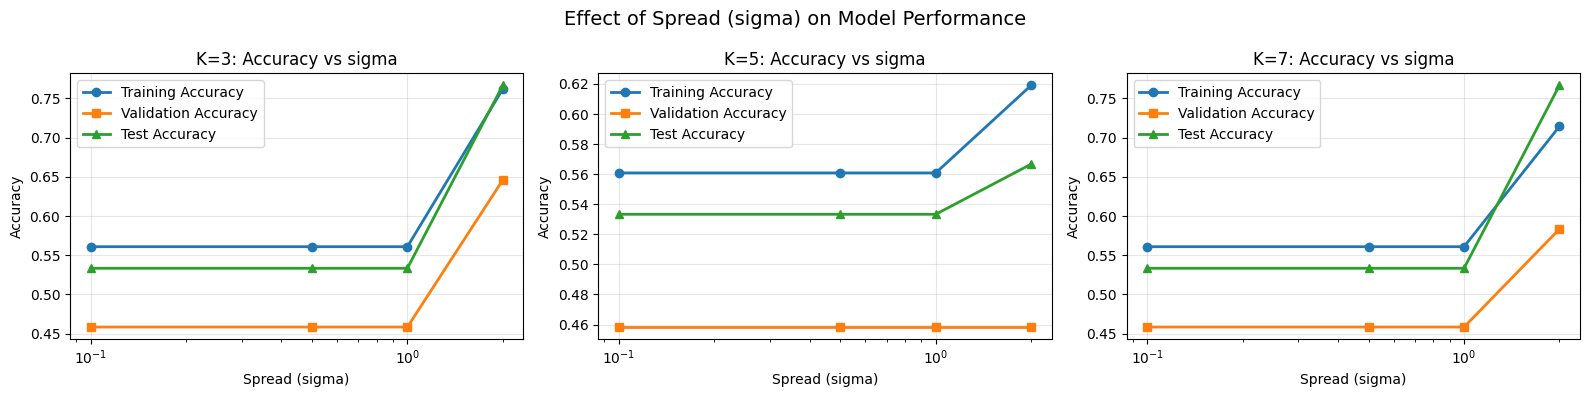

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, k in enumerate(k_values):
    ax = axes[idx]
    
    sigmas = []
    train_accs = []
    val_accs = []
    test_accs = []
    
    for sigma in sigma_values:
        sigmas.append(sigma)
        history = results[f'k_{k}'][f'sigma_{sigma}']['history']
        train_acc = history.history['accuracy'][-1]
        val_acc = history.history['val_accuracy'][-1]
        test_acc = results[f'k_{k}'][f'sigma_{sigma}']['metrics']['accuracy']
        
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        test_accs.append(test_acc)
    
    ax.plot(sigmas, train_accs, marker='o', label='Training Accuracy', linewidth=2)
    ax.plot(sigmas, val_accs, marker='s', label='Validation Accuracy', linewidth=2)
    ax.plot(sigmas, test_accs, marker='^', label='Test Accuracy', linewidth=2)
    ax.set_title(f'K={k}: Accuracy vs sigma')
    ax.set_xlabel('Spread (sigma)')
    ax.set_ylabel('Accuracy')
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xscale('log')

plt.suptitle('Effect of Spread (sigma) on Model Performance', fontsize=14)
plt.tight_layout()
plt.show()

In [81]:
comparison_data = []

for k in k_values:
    for sigma in sigma_values:
        config_results = results[f'k_{k}'][f'sigma_{sigma}']['metrics']
        comparison_data.append({
            'K': k,
            'sigma': sigma,
            'Accuracy': round(config_results['accuracy'], 4),
            'Precision': round(config_results['precision'], 4),
            'Recall': round(config_results['recall'], 4),
            'F1-Score': round(config_results['f1_score'], 4),
            'ROC-AUC': round(config_results['roc_auc'], 4)
        })

comparison_df = pd.DataFrame(comparison_data)
comparison_df

,K,sigma,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,3,0.1,0.5333,0.0000,0.0000,0.0000,0.5000
1,3,0.5,0.5333,0.0000,0.0000,0.0000,0.3471
2,3,1.0,0.5333,0.0000,0.0000,0.0000,0.2846
3,3,2.0,0.7667,1.0000,0.5000,0.6667,0.9353
4,5,0.1,0.5333,0.0000,0.0000,0.0000,0.5000
5,5,0.5,0.5333,0.0000,0.0000,0.0000,0.6847
6,5,1.0,0.5333,0.0000,0.0000,0.0000,0.1350
7,5,2.0,0.5667,1.0000,0.0714,0.1333,0.8850
8,7,0.1,0.5333,0.0000,0.0000,0.0000,0.5000
9,7,0.5,0.5333,0.0000,0.0000,0.0000,0.7556


from this we can. see that the overall the best accuract we got with k=3 sigma=2 and k=7 sigma=2. but overall the best one i see is k=3 and sigma=2